In [12]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# LOAD & PREPARE DATA
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')

target = 'converted'

# Identify features
categorical = ['industry', 'employment_status', 'lead_source', 'location']
numerical = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']

# Fill missing values
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

# Split into train/val/test
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1, stratify=df[target])
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1, stratify=df_full_train[target])

y_train = df_train[target].astype(int)

**Question 1: ROC AUC feature importance**

In [13]:
from sklearn.metrics import roc_auc_score

auc_scores = {}
for col in numerical:
    scores = df_train[col]
    auc = roc_auc_score(y_train, scores)
    
    # If AUC < 0.5, invert the variable
    if auc < 0.5:
        auc = roc_auc_score(y_train, -scores)
    
    auc_scores[col] = auc
    print(f"{col:25s} -> AUC: {auc:.3f}")


# Identify best feature
best_feature = max(auc_scores, key=auc_scores.get)
print(f"\nBest numerical feature by AUC: {best_feature} ({auc_scores[best_feature]:.3f})")

lead_score                -> AUC: 0.784
number_of_courses_viewed  -> AUC: 0.722
interaction_count         -> AUC: 0.758
annual_income             -> AUC: 0.620

Best numerical feature by AUC: lead_score (0.784)


**Question 2: Training the model**

In [14]:
# Identify categorical and numerical columns
categorical = df_train.select_dtypes(include='object').columns.tolist()
numerical = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']
features = categorical + numerical

# Fill missing values
for col in categorical:
    df_train[col] = df_train[col].fillna('NA')
    df_val[col] = df_val[col].fillna('NA')

for col in numerical:
    df_train[col] = pd.to_numeric(df_train[col], errors='coerce').fillna(0.0)
    df_val[col] = pd.to_numeric(df_val[col], errors='coerce').fillna(0.0)

# Convert to dict for DictVectorizer
train_dict = df_train[features].to_dict(orient='records')
val_dict = df_val[features].to_dict(orient='records')

# One-hot encoding
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dict)
X_val = dv.transform(val_dict)

# Train logistic regression
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, df_train['converted'].values)

# Predict and compute AUC
y_pred = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(df_val['converted'].values, y_pred)
round(auc, 3)

0.74

**Question 3: Precision and Recall**

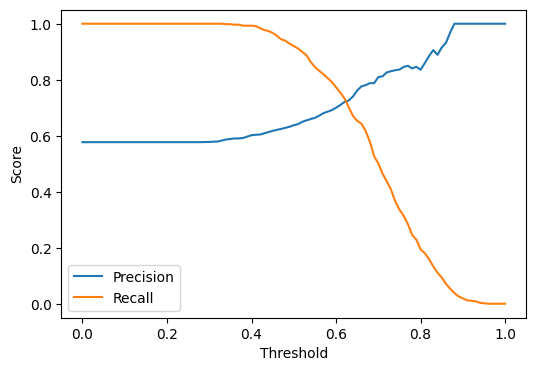

np.float64(0.62)

In [15]:
import numpy as np
from sklearn.metrics import precision_score, recall_score
import matplotlib.pyplot as plt

thresholds = np.arange(0.0, 1.01, 0.01)
precisions = []
recalls = []

y_true = df_val['converted'].values

for t in thresholds:
    y_pred_label = (y_pred >= t).astype(int)
    precisions.append(precision_score(y_true, y_pred_label, zero_division=1))
    recalls.append(recall_score(y_true, y_pred_label))

# Plot
plt.figure(figsize=(6,4))
plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.show()

# Find threshold where precision and recall are closest
diff = np.abs(np.array(precisions) - np.array(recalls))
best_threshold = thresholds[np.argmin(diff)]
best_threshold

**Question 4: F1 score**

Best threshold: 0.52
Maximum F1 score: 0.754


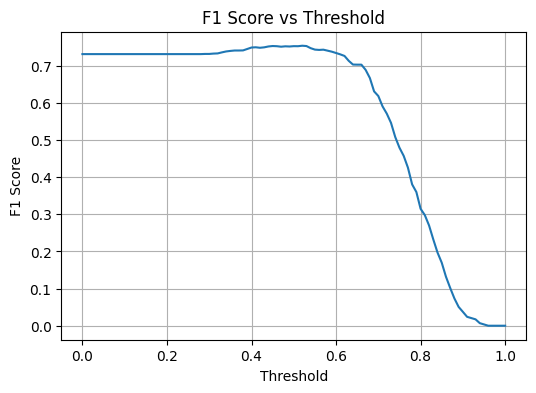

In [16]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

# Evaluate F1 for thresholds from 0.0 to 1.0
# with step 0.01
thresholds = np.arange(0.0, 1.01, 0.01)

f1_scores = []

y_true = df_val['converted'].values

for t in thresholds:
    # Convert probabilities to binary predictions
    y_pred_label = (y_pred >= t).astype(int)

    # Calculate F1 score
    score = f1_score(y_true, y_pred_label, zero_division=0)

    f1_scores.append(score)

# Find the threshold with the maximum F1 score
best_index = np.argmax(f1_scores)

best_threshold = thresholds[best_index]
best_f1 = f1_scores[best_index]

print("Best threshold:", round(best_threshold, 2))
print("Maximum F1 score:", round(best_f1, 3))

# Plot F1 score against threshold
plt.figure(figsize=(6, 4))
plt.plot(thresholds, f1_scores)
plt.xlabel('Threshold')
plt.ylabel('F1 Score')
plt.title('F1 Score vs Threshold')
plt.grid(True)
plt.show()


**Question 5: 5-Fold CV**

In [17]:
import numpy as np
import pandas as pd

from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Features and target
target = 'converted'

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

scores = []

for fold, (train_idx, val_idx) in enumerate(
    kf.split(df_full_train), start=1
):
    # Split into training and validation folds
    df_fold_train = df_full_train.iloc[train_idx].copy()
    df_fold_val = df_full_train.iloc[val_idx].copy()

    y_fold_train = df_fold_train[target].astype(int).values
    y_fold_val = df_fold_val[target].astype(int).values

    # Convert features to dictionaries
    train_dicts = (
        df_fold_train.drop(columns=[target])
        .to_dict(orient='records')
    )

    val_dicts = (
        df_fold_val.drop(columns=[target])
        .to_dict(orient='records')
    )

    # One-hot encoding
    dv = DictVectorizer(sparse=True)

    X_fold_train = dv.fit_transform(train_dicts)
    X_fold_val = dv.transform(val_dicts)

    # Train model
    model = LogisticRegression(
        solver='liblinear',
        C=1.0,
        max_iter=1000
    )

    model.fit(X_fold_train, y_fold_train)

    # Predict probabilities
    y_pred = model.predict_proba(X_fold_val)[:, 1]

    # Calculate AUC
    auc = roc_auc_score(y_fold_val, y_pred)
    scores.append(auc)

    print(f"Fold {fold}: AUC = {auc:.3f}")

# Mean and standard deviation
mean_auc = np.mean(scores)
std_auc = np.std(scores)

print("\nMean AUC:", round(mean_auc, 3))
print("Standard deviation:", round(std_auc, 3))


Fold 1: AUC = 0.765
Fold 2: AUC = 0.707
Fold 3: AUC = 0.741
Fold 4: AUC = 0.688
Fold 5: AUC = 0.737

Mean AUC: 0.728
Standard deviation: 0.027


**Question 6: Hyperparameter Tuning**

In [18]:
import numpy as np
import pandas as pd

from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

target = 'converted'
C_values = [0.000001, 0.001, 1]

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

results = []

for C in C_values:
    scores = []

    for train_idx, val_idx in kf.split(df_full_train):
        # Split data
        df_fold_train = df_full_train.iloc[train_idx].copy()
        df_fold_val = df_full_train.iloc[val_idx].copy()

        y_fold_train = df_fold_train[target].astype(int).values
        y_fold_val = df_fold_val[target].astype(int).values

        # Convert features to dictionaries
        train_dicts = (
            df_fold_train.drop(columns=[target])
            .to_dict(orient='records')
        )

        val_dicts = (
            df_fold_val.drop(columns=[target])
            .to_dict(orient='records')
        )

        # One-hot encoding
        dv = DictVectorizer(sparse=True)

        X_fold_train = dv.fit_transform(train_dicts)
        X_fold_val = dv.transform(val_dicts)

        # Train model with current C
        model = LogisticRegression(
            solver='liblinear',
            C=C,
            max_iter=1000
        )

        model.fit(X_fold_train, y_fold_train)

        # Predict probabilities and calculate AUC
        y_pred = model.predict_proba(X_fold_val)[:, 1]
        auc = roc_auc_score(y_fold_val, y_pred)

        scores.append(auc)

    # Calculate mean and standard deviation
    mean_auc = np.mean(scores)
    std_auc = np.std(scores)

    results.append({
        'C': C,
        'mean_auc': mean_auc,
        'std_auc': std_auc
    })

# Display results
results_df = pd.DataFrame(results)

print(results_df.round(3).to_string(index=False))

# Select best C by mean AUC
best_result = max(results, key=lambda x: x['mean_auc'])

print("\nBest C:", best_result['C'])
print("Mean AUC:", round(best_result['mean_auc'], 3))
print("Standard deviation:", round(best_result['std_auc'], 3))


    C  mean_auc  std_auc
0.000     0.619    0.023
0.001     0.750    0.027
1.000     0.728    0.027

Best C: 0.001
Mean AUC: 0.75
Standard deviation: 0.027
